# Measuring Ad Incrementality: Criteo Uplift Experiment

## Step 1: Framing the experiment

**Question:** Do ads *cause* more visits and conversions, by how much, and for which users?

Criteo ran a randomized experiment: users were randomly assigned to **treatment** (eligible to be shown ads, ~85%)
or **control** (held out from ads, ~15%). Because assignment is random, any difference in outcomes between the
groups is caused by the ads, not by who the users are.

| | Metric | Why |
|---|---|---|
| **Primary** | `visit` (did the user visit the advertiser's site?) | Common enough (~4.7%) to measure precisely |
| **Secondary** | `conversion` (did the user convert?) | What advertisers ultimately care about, but rare (~0.3%), so noisy |

**Hypothesis:** H₀: visit rate is the same in treatment and control. H₁: the rates differ (two-sided test, α = 0.05).

**Decision this informs:** Should ads be shown broadly, or targeted to the users most likely to be influenced by them?

**Data:** a seeded 10% random sample (`random_state=42`) of the Criteo Uplift Modeling Dataset v2.1
(Diemert et al., AdKDD 2018). Features `f0`–`f11` are anonymized and were measured *before* treatment.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_criteo, FEATURES
from src import validity

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../figures"

df = load_criteo(frac=0.10, seed=42)
print(f"{len(df):,} users x {df.shape[1]} columns")
df.head()

1,397,959 users x 16 columns


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,exposure,visit,conversion
0,21.2655,10.0597,8.2144,4.6799,10.2805,4.1155,-12.6418,4.8338,3.9719,13.1901,5.3004,-0.1687,0,0,0,0
1,25.7443,10.0597,8.2144,4.6799,10.2805,4.1155,-3.2821,4.8338,3.9719,13.1901,5.3004,-0.1687,1,0,0,0
2,12.6164,10.0597,8.8135,4.6799,10.2805,4.1155,0.2944,4.8338,3.9065,13.1901,5.3004,-0.1687,1,0,0,0
3,12.6164,10.0597,8.8763,4.6799,10.2805,4.1155,0.2944,4.8338,3.8959,13.1901,5.3004,-0.1687,1,0,0,0
4,12.6164,10.0597,9.0071,4.6799,10.2805,4.1155,0.2944,4.8338,3.8901,13.1901,5.3004,-0.1687,1,0,0,0


In [2]:
df[["treatment", "exposure", "visit", "conversion"]].mean().rename("share / rate").to_frame()

,share / rate
treatment,0.8503
exposure,0.0306
visit,0.0473
conversion,0.0030


## Step 2: Validity checks

Before reading any results, we confirm the experiment was run correctly. If randomization broke,
the treatment effect estimate can be biased, and no amount of statistics fixes that.

### 2a. Sample ratio mismatch (SRM)
The experiment intended an 85/15 split. A chi-square goodness-of-fit test asks: *if assignment really were 85/15,
how surprising are the counts we observe?* A very small p-value (common threshold: p < 0.001) would mean users
were lost or duplicated unevenly between arms (logging bugs, bots, redirects), and we should stop and debug.

In [3]:
srm = validity.srm_test(df, expected_treat_share=0.85)
pd.Series(srm).to_frame("value")

,value
n,"1,397,959.0000"
n_treatment,"1,188,739.0000"
n_control,"209,220.0000"
observed_treat_share,0.8503
expected_treat_share,0.8500
chi2,1.2597
p_value,0.2617


### 2b. Covariate balance
If randomization worked, pre-treatment features should look the same in both arms. We use the
**standardized mean difference** (SMD): the difference in means divided by the pooled standard deviation.
With 1.4M users, a t-test would call even trivially small differences "significant", so SMD is the better
measure of whether an imbalance is big enough to matter. Rule of thumb: |SMD| > 0.1 is a concern.

In [4]:
smd = validity.standardized_mean_diff(df, FEATURES)
smd

,feature,mean_treatment,mean_control,smd,imbalanced
0,f0,19.6218,19.6437,-0.0041,False
1,f1,10.0704,10.0677,0.0264,False
2,f2,8.4461,8.4493,-0.0106,False
3,f3,4.1705,4.2342,-0.0491,False
4,f4,10.3395,10.3364,0.0091,False
5,f5,4.0264,4.0388,-0.0297,False
6,f6,-4.1838,-3.9951,-0.0417,False
7,f7,5.1055,5.0831,0.0189,False
8,f8,3.9334,3.9346,-0.0205,False
9,f9,16.0449,15.8911,0.0222,False


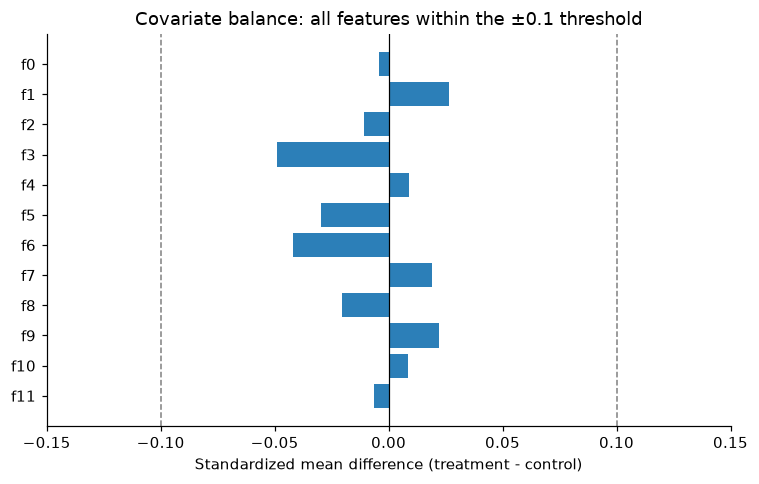

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(smd["feature"], smd["smd"], color=np.where(smd["imbalanced"], "#c0392b", "#2c7fb8"))
for x in (-0.1, 0.1):
    ax.axvline(x, color="grey", ls="--", lw=1)
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlim(-0.15, 0.15)
ax.set_xlabel("Standardized mean difference (treatment - control)")
ax.set_title("Covariate balance: all features within the ±0.1 threshold" if not smd["imbalanced"].any()
             else "Covariate balance: some features exceed ±0.1")
fig.tight_layout()
fig.savefig(f"{FIG}/01_covariate_balance.png", bbox_inches="tight")
plt.show()

### 2c. Exposure check
Being *assigned* to treatment doesn't guarantee seeing an ad (the user may never hit an ad auction Criteo wins).
Control users should **never** be exposed. This is "one-sided non-compliance", which matters later (Step 6) when we
estimate the effect on users who actually saw ads.

In [6]:
validity.exposure_check(df)

,n,n_exposed,exposure_rate
treatment,,,
control,209220,0,0.0000
treatment,1188739,42803,0.0360


In [7]:
exp = validity.exposure_check(df)
print(f"SRM: observed treatment share {srm['observed_treat_share']:.4f} vs 0.85 expected, p = {srm['p_value']:.3g}")
print(f"Balance: max |SMD| = {smd['smd'].abs().max():.4f} ({smd.loc[smd['smd'].abs().idxmax(), 'feature']}); "
      f"{int(smd['imbalanced'].sum())} features over 0.1")
print(f"Exposure: control exposure rate = {exp.loc['control', 'exposure_rate']:.4f} "
      f"({int(exp.loc['control', 'n_exposed'])} exposed control users); "
      f"treatment exposure rate = {exp.loc['treatment', 'exposure_rate']:.4f}")

SRM: observed treatment share 0.8503 vs 0.85 expected, p = 0.262
Balance: max |SMD| = 0.0491 (f3); 0 features over 0.1
Exposure: control exposure rate = 0.0000 (0 exposed control users); treatment exposure rate = 0.0360


## Step 3: Main effect (intent-to-treat)

We compare everyone *assigned* to treatment with everyone *assigned* to control, whether or not they actually saw
an ad. This is the **intent-to-treat (ITT)** effect. It's the effect of the *policy* "show ads to this population",
and it's protected by randomization (comparing only exposed users would not be).

- **Absolute lift** = treatment rate − control rate (in percentage points).
- **Relative lift** = treatment rate / control rate − 1 (how much higher, in %).
- **95% CI (absolute):** two-proportion normal approximation, SE = √(p_T(1−p_T)/n_T + p_C(1−p_C)/n_C).
- **95% CI (relative):** delta method on log(p_T / p_C), which keeps the interval correctly asymmetric.
- **p-value:** two-sided z-test using the pooled SE (the SE you'd expect if H₀ were true).

In [8]:
from src import effects
from src.data import OUTCOMES

itt = effects.lift_table(df, OUTCOMES)
itt_display = pd.DataFrame({
    "control rate": itt["control_rate"].map("{:.3%}".format),
    "treatment rate": itt["treatment_rate"].map("{:.3%}".format),
    "abs. lift (pp)": (itt["abs_lift"] * 100).map("{:+.3f}".format),
    "abs. 95% CI (pp)": [f"[{lo*100:.3f}, {hi*100:.3f}]" for lo, hi in zip(itt["abs_ci_low"], itt["abs_ci_high"])],
    "rel. lift": itt["rel_lift"].map("{:+.1%}".format),
    "rel. 95% CI": [f"[{lo:.1%}, {hi:.1%}]" for lo, hi in zip(itt["rel_ci_low"], itt["rel_ci_high"])],
    "p-value": itt["p_value"].map("{:.2g}".format),
})
itt_display

,control rate,treatment rate,abs. lift (pp),abs. 95% CI (pp),rel. lift,rel. 95% CI,p-value
metric,,,,,,,
visit,3.818%,4.885%,+1.067,"[0.976, 1.157]",+27.9%,"[25.0%, 30.9%]",9.2e-100
conversion,0.196%,0.320%,+0.123,"[0.102, 0.145]",+62.7%,"[47.0%, 80.1%]",2.6e-21


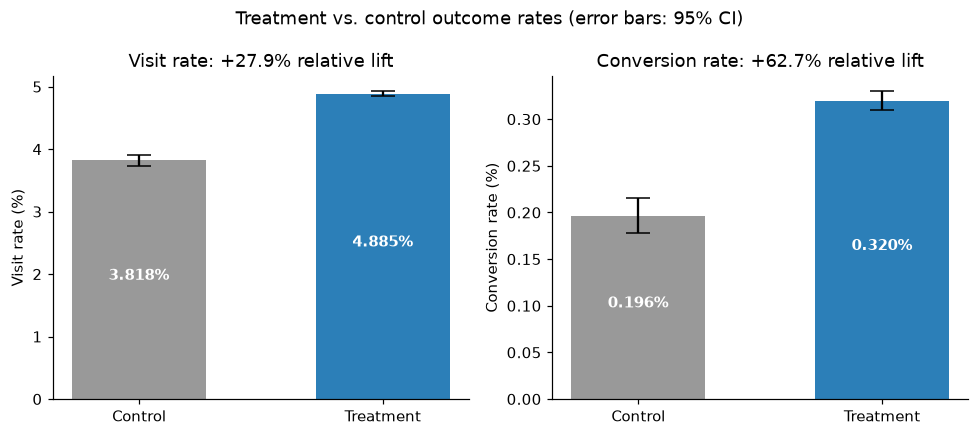

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, metric in zip(axes, OUTCOMES):
    rates = [effects.rate_ci(df.loc[df["treatment"] == t, metric]) for t in (0, 1)]
    p = np.array([r[0] for r in rates]) * 100
    err = np.array([[r[0] - r[1], r[2] - r[0]] for r in rates]).T * 100
    ax.bar(["Control", "Treatment"], p, yerr=err, capsize=8, color=["#999999", "#2c7fb8"], width=0.55)
    for i, v in enumerate(p):
        ax.text(i, v / 2, f"{v:.3f}%", ha="center", color="white", fontweight="bold")
    ax.set_title(f"{metric.capitalize()} rate: {itt.loc[metric, 'rel_lift']:+.1%} relative lift")
    ax.set_ylabel(f"{metric.capitalize()} rate (%)")
fig.suptitle("Treatment vs. control outcome rates (error bars: 95% CI)")
fig.tight_layout()
fig.savefig(f"{FIG}/02_rates_with_ci.png", bbox_inches="tight")
plt.show()

### Bootstrap check
The normal approximation assumes the sampling distribution of the lift is roughly normal. With rare outcomes
(conversion ≈ 0.3%) that's worth checking. The **bootstrap** resamples users with replacement within each arm,
recomputes the lift 1,000 times, and uses the middle 95% of those lifts as the CI, with no normality assumption.

Bootstrapping 1.4M users 1,000 times is slow, so we draw a 200,000-user subsample (keeping the 85/15 split) and
compare the bootstrap CI with the formula CI **on that same subsample**. If they agree there, the formula CIs on the
full data are trustworthy. The subsample CIs are wider than the full-data ones simply because n is smaller.

In [10]:
sub = effects.stratified_subsample(df, n=200_000, seed=42)
formula = effects.lift_table(sub, OUTCOMES)
boot = pd.DataFrame([effects.bootstrap_lift(sub, m, n_boot=1000, seed=42) for m in OUTCOMES]).set_index("metric")

pd.DataFrame({
    "abs. lift (pp)": (formula["abs_lift"] * 100).round(3),
    "formula 95% CI (pp)": [f"[{lo*100:.3f}, {hi*100:.3f}]" for lo, hi in zip(formula["abs_ci_low"], formula["abs_ci_high"])],
    "bootstrap 95% CI (pp)": [f"[{lo*100:.3f}, {hi*100:.3f}]" for lo, hi in zip(boot["abs_ci_low"], boot["abs_ci_high"])],
    "formula rel. CI": [f"[{lo:.1%}, {hi:.1%}]" for lo, hi in zip(formula["rel_ci_low"], formula["rel_ci_high"])],
    "bootstrap rel. CI": [f"[{lo:.1%}, {hi:.1%}]" for lo, hi in zip(boot["rel_ci_low"], boot["rel_ci_high"])],
    "share of resamples with lift <= 0": boot["share_boot_lift_le_0"],
})

,abs. lift (pp),formula 95% CI (pp),bootstrap 95% CI (pp),formula rel. CI,bootstrap rel. CI,share of resamples with lift <= 0
metric,,,,,,
visit,1.0840,"[0.843, 1.324]","[0.849, 1.309]","[20.8%, 36.4%]","[21.2%, 36.4%]",0.0000
conversion,0.1460,"[0.091, 0.201]","[0.092, 0.199]","[36.8%, 139.1%]","[41.8%, 145.2%]",0.0000


In [11]:
for m in OUTCOMES:
    r = itt.loc[m]
    print(f"{m}: {r['control_rate']:.3%} -> {r['treatment_rate']:.3%}; "
          f"abs lift {r['abs_lift']*100:+.3f} pp (95% CI [{r['abs_ci_low']*100:.3f}, {r['abs_ci_high']*100:.3f}]), "
          f"rel lift {r['rel_lift']:+.1%} (95% CI [{r['rel_ci_low']:.1%}, {r['rel_ci_high']:.1%}]), p = {r['p_value']:.2g}")

visit: 3.818% -> 4.885%; abs lift +1.067 pp (95% CI [0.976, 1.157]), rel lift +27.9% (95% CI [25.0%, 30.9%]), p = 9.2e-100
conversion: 0.196% -> 0.320%; abs lift +0.123 pp (95% CI [0.102, 0.145]), rel lift +62.7% (95% CI [47.0%, 80.1%]), p = 2.6e-21
